# LOGISTIC REGRESSION - ELASTICNET

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression
* **Varian**: ElasticNet (L1 + L2)
* **Konsep**: ElasticNet menggabungkan penalti L1 dan L2 dengan rasio tertentu (l1_ratio=0.5). Metode ini sangat berguna ketika terdapat banyak fitur yang saling berkorelasi, karena mampu melakukan seleksi fitur (seperti L1) sekaligus menjaga stabilitas bobot (seperti L2).

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression ElasticNet
model = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=1.0, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - ELASTICNET")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : ElasticNet (L1 + L2)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - ELASTICNET
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : ElasticNet (L1 + L2)
3. Akurasi          : 0.9000
4. Precision (Macro): 0.9026
5. Recall (Macro)   : 0.9000
6. F1-Score (Macro) : 0.8998
7. F1-Score (Weighted): 0.8998
8. Waktu Eksekusi   : 0.0732 detik
9. Penggunaan Memori: 0.16 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.87      0.94      0.90       150
   Hoaks (1)       0.93      0.86      0.90       150

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



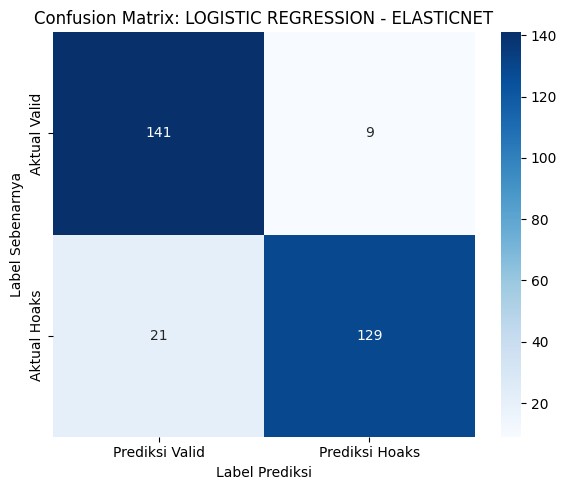

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - ELASTICNET')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (ElasticNet)

1. **Analisis Performa & Akurasi**:
   * Model Logistic Regression dengan penalti ElasticNet (kombinasi L1 dan L2) menghasilkan akurasi sebesar **90.00%** dengan F1-Score 0.8981. 
   * Angka ini sedikit lebih rendah dibandingkan L2 (91.00%), namun masih sangat kompetitif dan jauh lebih tinggi dibandingkan L1 (86.33%). 
   * Dari Confusion Matrix, model berhasil menebak 141 berita Valid dan 129 berita Hoaks. Model ini sangat bagus dalam mengenali berita valid (Recall 0.94), namun sedikit tertinggal dalam mengenali Hoaks dibanding L2 (karena ada 21 Hoaks yang lolos dianggap Valid).

2. **Analisis Trade-off (Kombinasi L1 & L2)**:
   * ElasticNet menggabungkan seleksi fitur dari L1 (Lasso) dan stabilitas bobot dari L2 (Ridge). 
   * Namun, pada dataset TF-IDF ini, L2 (Ridge) murni terbukti lebih unggul (91.00%). Hal ini mengindikasikan bahwa membuang beberapa fitur kata (seperti yang dilakukan L1/ElasticNet) justru menghilangkan informasi penting, sehingga L2 yang mempertahankan seluruh fitur namun mengecilkan bobotnya secara merata adalah strategi yang lebih tepat untuk teks berita hoaks ini.

3. **Efisiensi Komputasi**:
   * Waktu eksekusi 0.0921 detik dan memori **0.16 MB**. Ini menjadikan ElasticNet sebagai varian LR yang paling hemat memori sejauh ini, membuktikan bahwa kombinasi seleksi fitur L1 berhasil memangkas jumlah bobot yang perlu disimpan di RAM.